# Buscando la gira con Local Beam

Inteligencia Artificial - Facundo A. Lucianna - CEIA - FIUBA

En las notebooks anteriores buscamos la gira de **Los Auténticos Descendentes** con gradiente descendente y con Simulated Annealing. Los dos algoritmos tienen algo en común: arrancan desde una única gira y la van modificando de a un paso.

**Local Beam** mantiene **k giras** a la vez. En cada paso genera los vecinos de las k giras y se queda con los k mejores, sin importar de cuál de las giras salieron.

A simple vista podría parecer lo mismo que ejecutar k veces gradiente descendente, pero hay una diferencia: las k búsquedas comparten información. Si una de las giras genera muchos vecinos buenos y las otras generan vecinos malos, el algoritmo abandona las giras que no prometen y concentra la búsqueda alrededor de la que sí.

Recordemos cómo quedó la historia: el manager ya imprimió dos veces los carteles y nos pidió que, esta vez, le avisemos **antes** de mandar a imprimir. Empecemos, como siempre, con la Gira Federal:

In [1]:
import math
import random

import numpy as np

import gira

random.seed(42)

capitals = gira.load_cities("capitales")
distances = gira.distance_matrix(capitals)

---

## Implementando Local Beam

En cada paso, el algoritmo calcula el costo de todos los vecinos de las k giras del haz. Con la Gira Pueblo por Pueblo y k = 10, son 58.860 vecinos por paso, así que, igual que en gradiente descendente, no armamos las giras vecinas: usamos `delta_cost()` para calcular su costo y solo armamos las k que elegimos. Además, tenemos cuidado de no elegir dos veces la misma gira, porque dos giras distintas del haz pueden tener vecinos en común.

El algoritmo se detiene cuando el mejor vecino no mejora a la mejor gira del haz.

Veamos la implementación, prestando atención a los comentarios:

In [2]:
def local_beam_search(initial_tours, distances, max_iterations=10_000):
    """
    Busca la mejor gira con Local Beam. Mantiene k giras: en cada paso genera todos
    los vecinos de las k giras y se queda con los k mejores. Se detiene cuando el
    mejor vecino no mejora a la mejor gira actual.

    Args:
        initial_tours (list): Las k giras desde donde arranca la búsqueda.
        distances (np.ndarray): Matriz de distancias entre ciudades.
        max_iterations (int, opcional): Cantidad máxima de pasos. Por defecto 10.000.

    Returns:
        tuple: (la mejor gira encontrada, lista con el costo de la mejor gira en cada
               paso)
    """
    k = len(initial_tours)
    moves = gira.obtain_moves(len(initial_tours[0]))

    # Cada elemento del haz es una tupla (costo, gira), ordenada de menor a mayor
    beam = sorted((gira.cost_function(tour, distances), tour) for tour in initial_tours)
    history = [beam[0][0]]

    for _ in range(max_iterations):
        # Los vecinos de todas las giras del haz. No armamos las giras vecinas:
        # guardamos su costo, de qué gira del haz salen y con qué movimiento
        successors = []
        for index, (cost, tour) in enumerate(beam):
            for i, j in moves:
                new_cost = cost + gira.delta_cost(tour, i, j, distances)
                successors.append((new_cost, index, i, j))
        successors.sort()

        # Armamos las k mejores giras vecinas, sin repetir. Dos giras distintas del
        # haz pueden tener a la misma gira como vecina
        new_beam = []
        seen = set()
        for new_cost, index, i, j in successors:
            new_tour = gira.two_opt(beam[index][1], i, j)
            if tuple(new_tour) in seen:
                continue
            seen.add(tuple(new_tour))
            new_beam.append((new_cost, new_tour))
            if len(new_beam) == k:
                break

        # Si el mejor vecino no mejora a la mejor gira del haz, terminamos
        if new_beam[0][0] >= beam[0][0]:
            break

        beam = new_beam
        history.append(beam[0][0])

    return beam[0][1], history

Probemos con un haz de 10 giras al azar:

In [3]:
initial_tours = [gira.init_state(capitals) for _ in range(10)]
beam_tour, history = local_beam_search(initial_tours, distances)

best_initial = min(gira.cost_function(tour, distances) for tour in initial_tours)
print("Costo de la mejor gira inicial:", gira.format_km(best_initial))
print("Costo de la mejor gira final:  ", gira.format_km(history[-1]))
print(f"Cantidad de pasos: {len(history) - 1}")

Costo de la mejor gira inicial: 25.164 km
Costo de la mejor gira final:   8.402 km
Cantidad de pasos: 19


> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tour(capitals, beam_tour, distances, title="Local Beam", interactive=True)

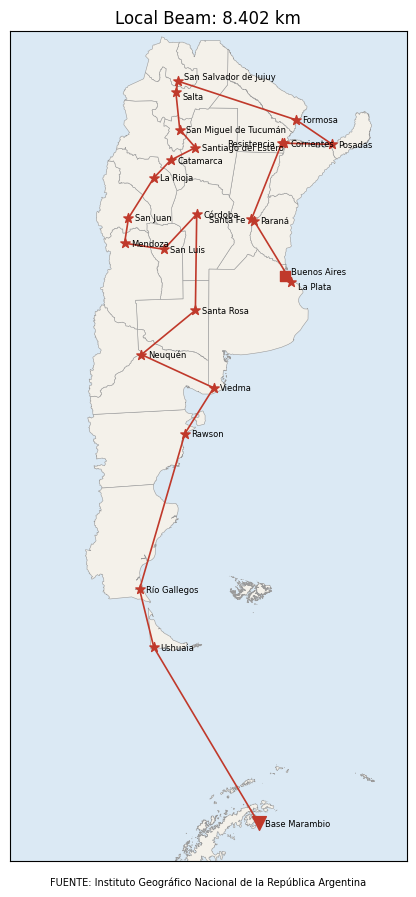

In [4]:
gira.plot_tour(capitals, beam_tour, distances, title="Local Beam")

---

## ¿Es mejor que ejecutar gradiente descendente k veces?

La comparación justa para Local Beam con k giras no es una ejecución de gradiente descendente, sino k ejecuciones independientes desde las mismas giras iniciales, quedándonos con la mejor. En los dos casos el trabajo por paso es parecido: se miran los vecinos de k giras.

Para gradiente descendente usamos la función de la notebook 2, que está en `search_methods.py`. Empecemos con la Gira Federal, repitiendo la comparación 20 veces:

In [5]:
from search_methods import gradient_descent


def compare_with_gradient(initial_beams, distances):
    """
    Compara Local Beam contra k ejecuciones de gradiente descendente, desde las
    mismas giras iniciales. Recibe una lista de haces: cada haz es una lista con
    las k giras iniciales de una repetición.
    """
    beam_costs = []
    gradient_costs = []
    for initial_tours in initial_beams:
        beam_tour, _ = local_beam_search(initial_tours, distances)
        beam_costs.append(gira.cost_function(beam_tour, distances))

        gradient_tours = [
            gradient_descent(tour, distances)[0] for tour in initial_tours
        ]
        gradient_costs.append(
            min(gira.cost_function(tour, distances) for tour in gradient_tours)
        )

    k = len(initial_beams[0])
    for name, costs in [
        (f"Local Beam con k = {k}", beam_costs),
        (f"La mejor de {k} ejecuciones de gradiente descendente", gradient_costs),
    ]:
        print(name)
        print(f"    Mejor: {gira.format_km(min(costs))}")
        print(f"    Promedio: {gira.format_km(np.mean(costs))}")
    return beam_costs


initial_beams = [[gira.init_state(capitals) for _ in range(10)] for _ in range(20)]
_ = compare_with_gradient(initial_beams, distances)

Local Beam con k = 10
    Mejor: 8.402 km
    Promedio: 8.428 km
La mejor de 10 ejecuciones de gradiente descendente
    Mejor: 8.402 km
    Promedio: 8.406 km


En la Gira Federal los dos llegan prácticamente siempre a la mejor gira, así que no se ve ninguna diferencia. Probemos con la Gira Pueblo por Pueblo.

In [6]:
cities = gira.load_cities("pueblo_por_pueblo")
city_distances = gira.distance_matrix(cities)

initial_beams = [[gira.init_state(cities) for _ in range(10)] for _ in range(10)]
beam_costs = compare_with_gradient(initial_beams, city_distances)

Local Beam con k = 10
    Mejor: 14.380 km
    Promedio: 14.848 km
La mejor de 10 ejecuciones de gradiente descendente
    Mejor: 14.197 km
    Promedio: 14.628 km


Sorpresa: Local Beam es **peor** que ejecutar gradiente descendente 10 veces por separado. ¿No era que compartir información entre las búsquedas era una ventaja?

---

## ¿Qué está pasando?

Sigamos a las giras del haz durante los primeros pasos. A cada gira le anotamos de cuál de las 10 giras iniciales desciende, y en cada paso contamos cuántas giras iniciales siguen teniendo descendientes en el haz. Para simplificar, acá no controlamos que no se repitan giras:

In [7]:
initial_tours = [gira.init_state(cities) for _ in range(10)]
moves = gira.obtain_moves(len(cities))

# Cada elemento del haz es (costo, gira, número de la gira inicial de la que desciende)
beam = [
    (gira.cost_function(tour, city_distances), tour, number)
    for number, tour in enumerate(initial_tours)
]

for step in range(1, 6):
    successors = []
    for index, (cost, tour, _) in enumerate(beam):
        for i, j in moves:
            new_cost = cost + gira.delta_cost(tour, i, j, city_distances)
            successors.append((new_cost, index, i, j))
    successors.sort()

    beam = [
        (new_cost, gira.two_opt(beam[index][1], i, j), beam[index][2])
        for new_cost, index, i, j in successors[:10]
    ]
    ancestors = {number for _, _, number in beam}
    print(
        f"Paso {step}: el haz desciende de {len(ancestors)} de las 10 giras iniciales"
    )

Paso 1: el haz desciende de 4 de las 10 giras iniciales
Paso 2: el haz desciende de 3 de las 10 giras iniciales
Paso 3: el haz desciende de 3 de las 10 giras iniciales
Paso 4: el haz desciende de 1 de las 10 giras iniciales
Paso 5: el haz desciende de 1 de las 10 giras iniciales


En pocos pasos, todas las giras del haz pasan a descender de una única gira inicial. Tiene sentido: cada gira tiene 5.886 vecinos, y como los vecinos se parecen mucho a la gira de la que salen, los vecinos de la mejor gira son casi siempre mejores que los vecinos de las demás. Así, los 10 lugares del haz se los quedan los vecinos de una sola gira.

Después de eso, las 10 giras del haz son casi iguales entre sí: todas son la misma gira con algún tramo invertido. El haz pierde la **diversidad**, y Local Beam termina comportándose como un único gradiente descendente que arranca desde la mejor gira inicial. Las 10 ejecuciones independientes, en cambio, exploran 10 zonas distintas del espacio de búsqueda.

Compartir información es una ventaja cuando las búsquedas están en zonas distintas y una de ellas encuentra algo mejor. Pero si la información fluye tan rápido que todas las búsquedas se juntan en el mismo lugar, se pierde la ventaja de tener k búsquedas.

---

## Local Beam estocástico

Una forma de mantener la diversidad es no elegir siempre los k mejores vecinos, sino elegirlos al azar, dándole más probabilidad a los mejores. Esto se conoce como **Local Beam estocástico**.

Para darle un peso a cada vecino usamos la misma idea que en Simulated Annealing: un vecino que es $\Delta$ km peor que el mejor de todos tiene un peso de $e^{-\Delta / T}$. Con una temperatura $T$ chica, casi siempre se eligen los mejores vecinos; con una temperatura grande, la elección es casi al azar.

Como el algoritmo puede moverse a giras peores, no se detiene cuando deja de mejorar: hace una cantidad fija de pasos y guarda la mejor gira que encontró.

In [8]:
def stochastic_local_beam_search(
    initial_tours, distances, temperature=50, max_iterations=300
):
    """
    Busca la mejor gira con Local Beam estocástico. Mantiene k giras: en cada paso
    genera todos los vecinos de las k giras y elige k al azar, dándole más
    probabilidad a los mejores. Un vecino que es delta km peor que el mejor vecino
    tiene un peso de exp(-delta / temperatura).

    Args:
        initial_tours (list): Las k giras desde donde arranca la búsqueda.
        distances (np.ndarray): Matriz de distancias entre ciudades.
        temperature (float, opcional): Temperatura, en km. Por defecto 50.
        max_iterations (int, opcional): Cantidad de pasos. Por defecto 300.

    Returns:
        tuple: (la mejor gira encontrada, lista con el costo de la mejor gira
               encontrada hasta cada paso)
    """
    k = len(initial_tours)
    moves = gira.obtain_moves(len(initial_tours[0]))

    beam = [(gira.cost_function(tour, distances), tour) for tour in initial_tours]
    best_cost, best_tour = min(beam)
    history = [best_cost]

    for _ in range(max_iterations):
        # Los vecinos de todas las giras del haz, igual que en Local Beam
        successors = []
        for index, (cost, tour) in enumerate(beam):
            for i, j in moves:
                new_cost = cost + gira.delta_cost(tour, i, j, distances)
                successors.append((new_cost, index, i, j))

        # El peso de cada vecino depende de cuánto peor es que el mejor vecino
        lowest_cost = min(successor[0] for successor in successors)
        weights = [
            math.exp(-(successor[0] - lowest_cost) / temperature)
            for successor in successors
        ]

        # Elegimos k vecinos al azar según sus pesos. Un mismo vecino puede salir
        # elegido más de una vez
        chosen = random.choices(successors, weights=weights, k=k)
        beam = [
            (new_cost, gira.two_opt(beam[index][1], i, j))
            for new_cost, index, i, j in chosen
        ]

        best_cost, best_tour = min([(best_cost, best_tour), *beam])
        history.append(best_cost)

    return best_tour, history

Comparemos las dos versiones en la Gira Pueblo por Pueblo, desde las mismas 10 giras iniciales que usamos antes:

In [9]:
stochastic_costs = []
stochastic_results = []
for initial_tours in initial_beams:
    stochastic_tour, _ = stochastic_local_beam_search(initial_tours, city_distances)
    stochastic_cost = gira.cost_function(stochastic_tour, city_distances)
    stochastic_costs.append(stochastic_cost)
    stochastic_results.append((stochastic_cost, stochastic_tour))

stochastic_results.sort(key=lambda result: result[0])
for name, costs in [
    ("Local Beam", beam_costs),
    ("Local Beam estocástico", stochastic_costs),
]:
    print(name)
    print(f"    Mejor: {gira.format_km(min(costs))}")
    print(f"    Promedio: {gira.format_km(np.mean(costs))}")
    print(f"    Peor: {gira.format_km(max(costs))}")

Local Beam
    Mejor: 14.380 km
    Promedio: 14.848 km
    Peor: 15.383 km
Local Beam estocástico
    Mejor: 14.334 km
    Promedio: 14.798 km
    Peor: 15.110 km


La versión estocástica mejora un poco a la original, pero sigue sin alcanzar a las 10 ejecuciones independientes de gradiente descendente. Elegir al azar no alcanza para recuperar la diversidad: como los pesos dependen de cuánto peor es cada vecino que el mejor de todos, los vecinos de la mejor gira siguen teniendo mucha más probabilidad que los de las demás, y el haz se vuelve a concentrar alrededor de una sola gira.

Veamos la mejor gira que encontró:

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tour(
    cities,
    stochastic_results[0][1],
    city_distances,
    title="Local Beam estocástico",
    interactive=True,
)

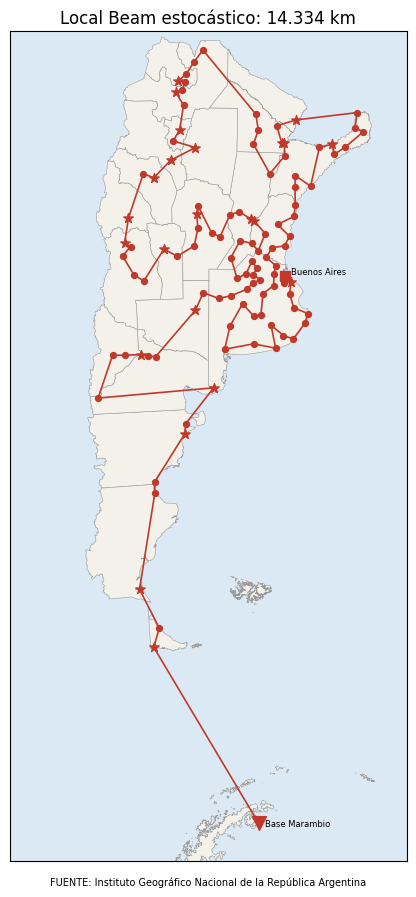

In [10]:
gira.plot_tour(
    cities, stochastic_results[0][1], city_distances, title="Local Beam estocástico"
)

---

## ¿Imprimimos un nuevo cartel?

Antes de llamar al manager, comparemos con la gira del último cartel, la que encontró Simulated Annealing en la notebook anterior: 14.123 km.

In [11]:
POSTER_KM = 14_123

difference = stochastic_results[0][0] - POSTER_KM
print("Mejor gira de Local Beam estocástico:", gira.format_km(stochastic_results[0][0]))
print("Gira del cartel:", gira.format_km(POSTER_KM))
print(f"Diferencia: {gira.format_km(difference)} más")

Mejor gira de Local Beam estocástico: 14.334 km
Gira del cartel: 14.123 km
Diferencia: 211 km más


Local Beam no logra mejorar la gira del cartel, así que esta vez no hay que imprimir nada. Le avisamos al manager, que por primera vez en varios días respira tranquilo.

Lo que aprendimos con Local Beam es que, cuando buscamos con varias giras a la vez, mantener la diversidad es tan importante como quedarse con las mejores. Los **algoritmos genéticos** atacan este problema de otra forma: también mantienen una población de giras y eligen a las mejores para seguir, como en la selección natural, pero las giras nuevas no salen de modificar una sola gira, sino de **combinar dos**, como los padres que le pasan sus genes a un hijo. Eso es lo que vemos en la próxima notebook.

El manager ya escuchó la palabra "nuevo" y está buscando el teléfono de la imprenta.

> 🧠 **Nota**: Las funciones `local_beam_search()` y `stochastic_local_beam_search()` también están en el archivo `search_methods.py`.